In [1]:
import pandas as pd
import numpy as np
#data viz 
import plotly.graph_objs as go
import plotly.express as px
#f in data sources
import yfinance as yf
import pandas_datareader as pdr
#time
import time
from datetime import date

UNDERSTANDING DATA-DRIVEN DECISIONS DATA-PULL

In [2]:
end=date.today()
print(f'year = {end.year}; month = {end.month}; day = {end.day}')
start=date(year = end.year-70, month = end.month, day = end.day)
print(f'period for indexes:{start} to {end}')

year = 2026; month = 11; day = 5
period for indexes:1956-11-05 to 2026-11-05


In [3]:
#Real Potential Gross Domestic Product(GDPPOT),Billions of chained 2012 Dollars,Quartely
#https://fred.stlouisfed.org/series/GDPPOT
gdppot=pdr.DataReader("GDPPOT", "fred", start=start)

In [4]:
gdppot['gdppot_us_yoy'] = gdppot.GDPPOT/gdppot.GDPPOT.shift(4)-1
gdppot['gdppot_us_qoq'] = gdppot.GDPPOT/gdppot.GDPPOT.shift(4)-1
gdppot.tail()

,GDPPOT,gdppot_us_yoy,gdppot_us_qoq
DATE,,,
2025-10-01,23811.223897,0.023191,0.023191
2026-01-01,23945.137839,0.022656,0.022656
2026-04-01,24070.938648,0.022185,0.022185
2026-07-01,24200.444694,0.021972,0.021972
2026-10-01,24330.374529,0.021803,0.021803


In [5]:
import pandas_datareader.wb as wb

# search for Kenya GDP indicators
wb.search('GDP').iloc[0:10]

# fetch, e.g., Kenya real GDP
kenya_gdp = wb.download(indicator='NY.GDP.MKTP.KD', country='KE', start=2000, end=2025)
kenya_gdp.head()

/var/folders/2d/1c91gggs08n6vxd8g4bhwqmc0001yj/T/ipykernel_81101/1322545836.py:7: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  kenya_gdp = wb.download(indicator='NY.GDP.MKTP.KD', country='KE', start=2000, end=2025)


NY.GDP.MKTP.KD
country year                
Kenya   2025    1.097616e+11
        2024    1.049019e+11
        2023    1.002309e+11
        2022    9.480791e+10
        2021    9.041382e+10

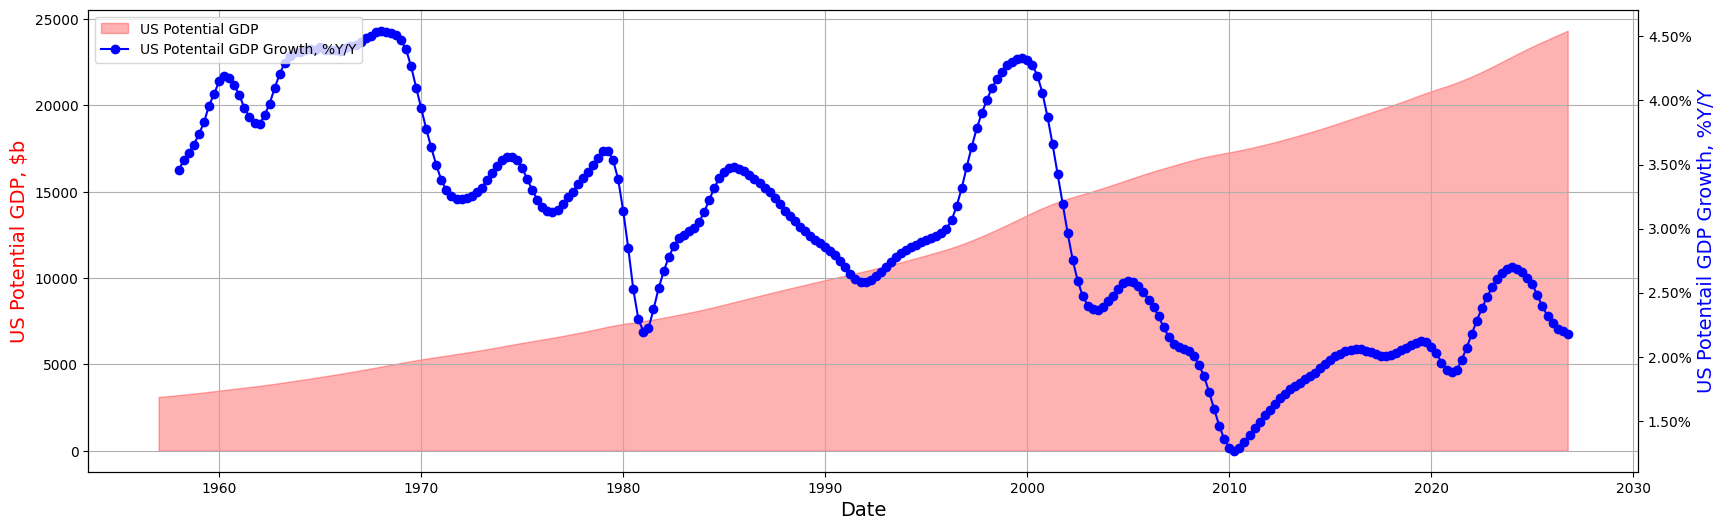

In [6]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

fig,ax =plt.subplots(figsize=(20,6))
plt.grid(True)

#plotting area under us potential GDP curve
ax.fill_between(gdppot.index, gdppot.GDPPOT, color ="red", alpha=0.3, label="US Potential GDP")

#creating a secondary y-axis for GDP growth percentage
ax2 = ax.twinx()
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax2.plot(gdppot.gdppot_us_yoy,color = "blue", marker="o", label ="US Potentail GDP Growth, %Y/Y")

#setting labels and titles
ax.set_xlabel("Date", fontsize = 14)
ax.set_ylabel("US Potential GDP, $b",color="red",fontsize = 14)
ax2.set_ylabel("US Potentail GDP Growth, %Y/Y" , color="blue", fontsize=14)

#Adding legend
lines,label = ax.get_legend_handles_labels()
lines2,labels2=ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, label + labels2, loc='upper left')
plt.show()

In [7]:
## "Core-CPI Index",MONTHLY 
#https://fred.stlouis.org/series/CPILFESL
#The "Consumer Price Index of all urban consumers:All items less Food & Energy"
#This is an aggregate of prices paid by urban consumers for a typical basket of goods,excluding food and energy
#This measurement known as "Core CPI" is widely  used by economists because food and energy have very volatile prices.
cpilfesl= pdr.DataReader("CPILFESL","fred",start = start)

cpilfesl['cpi_core_yoy'] = cpilfesl.CPILFESL/cpilfesl.CPILFESL.shift(12)-1
cpilfesl['cpi_core_mom'] = cpilfesl.CPILFESL/cpilfesl.CPILFESL.shift(1)-1
cpilfesl.tail(13)

,CPILFESL,cpi_core_yoy,cpi_core_mom
DATE,,,
2025-09-01,330.418,0.030200,0.002178
2025-10-01,NaN,NaN,NaN
2025-11-01,331.043,0.025990,NaN
2025-12-01,331.814,0.026465,0.002329
2026-01-01,332.793,0.025120,0.002950
2026-02-01,333.512,0.024725,0.002161
2026-03-01,334.165,0.026022,0.001958
2026-04-01,335.423,0.027433,0.003765
2026-05-01,336.121,0.028229,0.002081


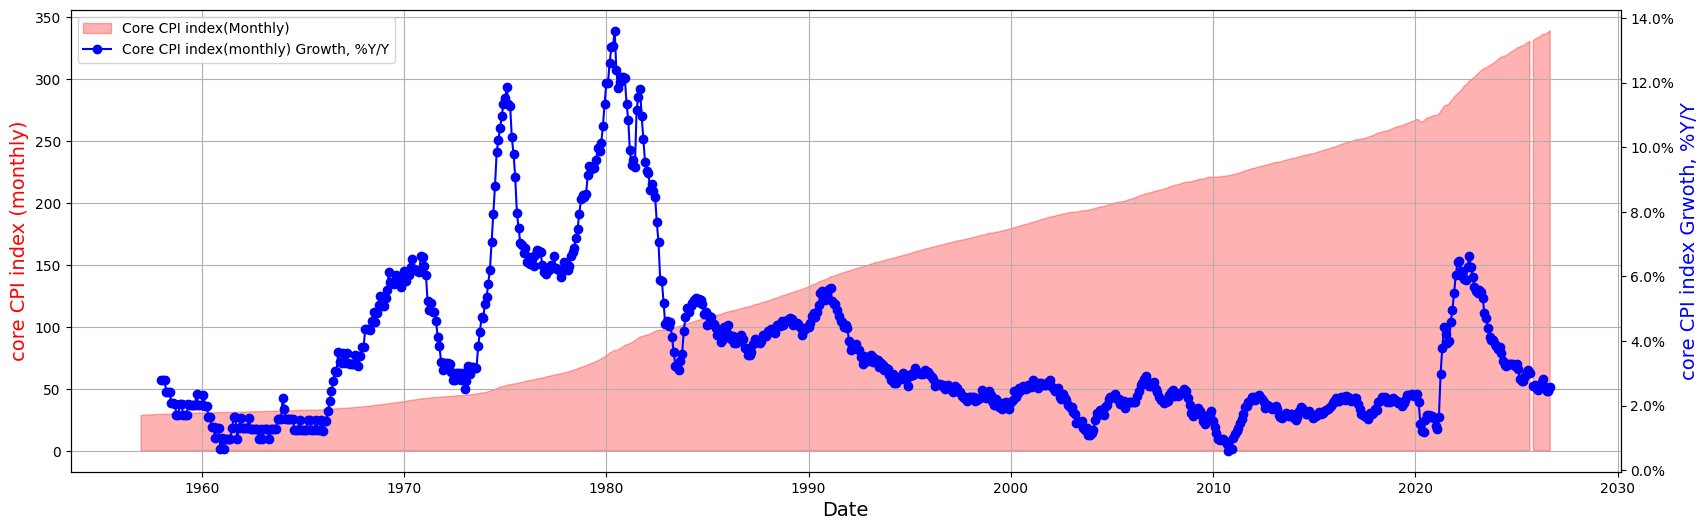

In [8]:
fig, ax = plt.subplots(figsize=(20, 6))
plt.grid(True)

#plotting area under cpi
ax.fill_between(cpilfesl.index, cpilfesl.CPILFESL, color="red", alpha = 0.3, label ="Core CPI index(Monthly)")

#creating secondary y-axis for CPI growth percentage
ax2 = ax.twinx()
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax2.plot(cpilfesl.cpi_core_yoy, color="blue", marker="o", label="Core CPI index(monthly) Growth, %Y/Y")

#setting labels and title
ax.set_xlabel("Date", fontsize=14)
ax.set_ylabel("core CPI index (monthly)", color="red", fontsize=14)
ax2.set_ylabel("core CPI index Grwoth, %Y/Y", color="blue", fontsize=14)

#Adding legend
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc= 'upper left')

plt.show()

In [9]:
#fedrate https://fred.stlouis.org/series/FEDFUNDS
fedfunds = pdr.DataReader("FEDFUNDS","fred", start=start )
fedfunds.tail()

,FEDFUNDS
DATE,
2026-06-01,3.63
2026-07-01,3.63
2026-08-01,3.63
2026-09-01,3.75
2026-10-01,3.88


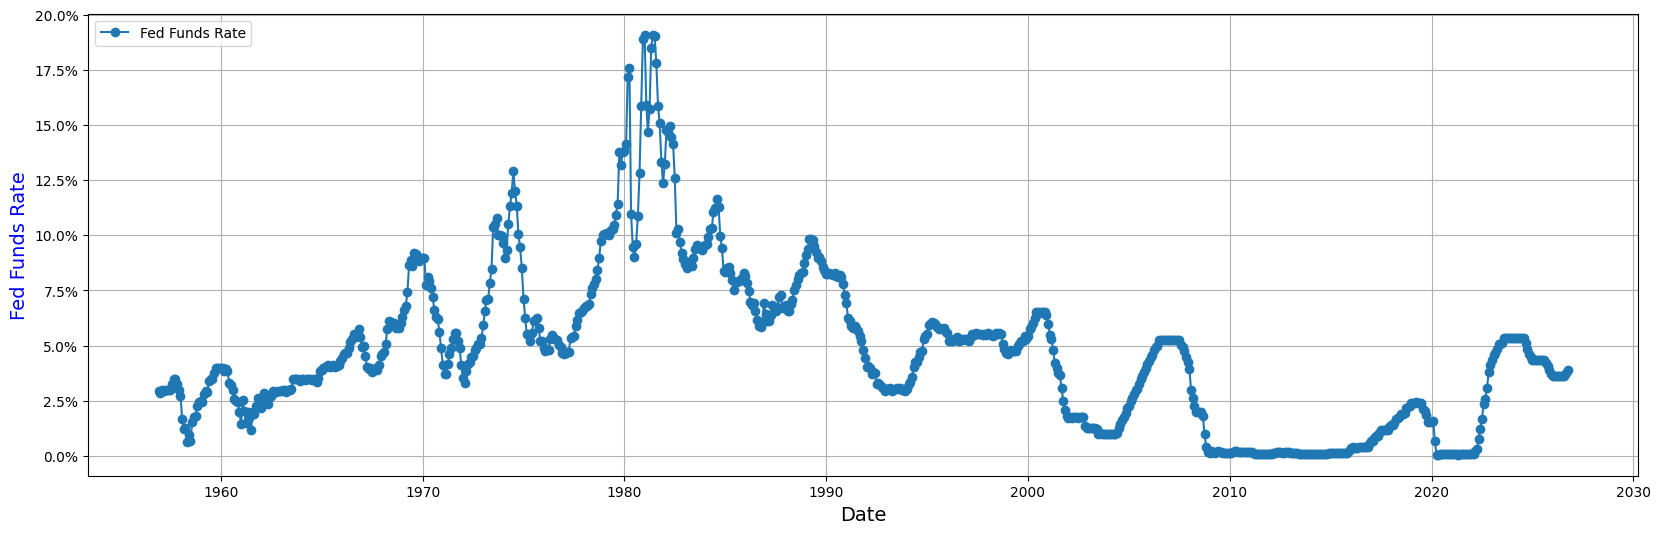

In [10]:
#Fed funds
fig,ax = plt.subplots(figsize =(20,6))
plt.grid(True)


ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.plot(fedfunds.index, fedfunds.FEDFUNDS/100, marker = "o", label = "Fed Funds Rate")

#setting labels and titles
ax.set_xlabel("Date", fontsize=14)
ax.set_ylabel("Fed Funds Rate",color = 'blue',fontsize = 14)

#Adding legend
lines,labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc ='upper left')

plt.show()

In [11]:
#https://fred.stlouisfed.org/series/DGS1
dgs1=pdr.DataReader("DGS1","fred", start=start)
dgs1.tail()

,DGS1
DATE,
2026-10-28,4.47
2026-10-29,4.42
2026-10-30,4.36
2026-11-02,4.38
2026-11-03,4.40


In [12]:
# https://fred.stlouisfed.org/series/DGS5
dgs5 = pdr.DataReader("DGS5", "fred", start=start)
dgs5.tail()
     

,DGS5
DATE,
2026-10-28,4.85
2026-10-29,4.78
2026-10-30,4.71
2026-11-02,4.70
2026-11-03,4.74


In [13]:
# Other indexes: https://stooq.com/t/

# SPX= S&P500
#spx_index = pdr.get_data_stooq('^SPX', start, end)
#spx_index.head()

In [14]:
#since stooq is not allowed we are using yfinance and s&p 500 index for it is ^GSPC contrary to stooq's SPX

spx_index = yf.download("^GSPC", start=start, end=end)  # ^GSPC is Yahoo's S&P 500 ticker
spx_index.tail()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,
2026-10-29,7720.390137,7732.209961,7690.939941,7699.609863,5827600000
2026-10-30,7580.069824,7637.479980,7527.560059,7631.069824,6149170000
2026-11-02,7541.399902,7662.229980,7539.379883,7610.830078,5712790000
2026-11-03,7568.919922,7594.609863,7545.390137,7552.919922,5481240000
2026-11-04,7688.620117,7715.569824,7635.810059,7635.810059,7390830000


In [15]:
# 252 trading days a year

spx_index['spx_dod'] = spx_index.Close/spx_index.Close.shift(1)-1
spx_index['spx_qoq'] = spx_index.Close/spx_index.Close.shift(63)-1
spx_index['spx_yoy'] = spx_index.Close/spx_index.Close.shift(252)-1

In [16]:
spx_index.tail()

Price,Close,High,Low,Open,Volume,spx_dod,spx_qoq,spx_yoy
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,,,
Date,,,,,,,,
2026-10-29,7720.390137,7732.209961,7690.939941,7699.609863,5827600000,-0.003046,0.030798,0.120376
2026-10-30,7580.069824,7637.479980,7527.560059,7631.069824,6149170000,-0.018175,-0.002688,0.100061
2026-11-02,7541.399902,7662.229980,7539.379883,7610.830078,5712790000,-0.005102,-0.025221,0.105398
2026-11-03,7568.919922,7594.609863,7545.390137,7552.919922,5481240000,0.003649,-0.020021,0.106535
2026-11-04,7688.620117,7715.569824,7635.810059,7635.810059,7390830000,0.015815,-0.002768,0.122104


In [17]:
spx_truncated = spx_index[spx_index.index >= '1990-01-01']
spx_truncated

Price,Close,High,Low,Open,Volume,spx_dod,spx_qoq,spx_yoy
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,,,
Date,,,,,,,,
1990-01-02,359.690002,359.690002,351.980011,353.399994,162070000,0.017799,0.025138,0.306491
1990-01-03,358.760010,360.589996,357.890015,359.690002,192330000,-0.002586,0.011418,0.283899
1990-01-04,355.670013,358.760010,352.890015,358.760010,177000000,-0.008613,-0.003558,0.270205
1990-01-05,352.200012,355.670013,351.350006,355.670013,158530000,-0.009756,-0.013362,0.254854
1990-01-08,353.790009,354.239990,350.540009,352.200012,140110000,0.004514,-0.013908,0.259129
...,...,...,...,...,...,...,...,...
2026-10-29,7720.390137,7732.209961,7690.939941,7699.609863,5827600000,-0.003046,0.030798,0.120376
2026-10-30,7580.069824,7637.479980,7527.560059,7631.069824,6149170000,-0.018175,-0.002688,0.100061


In [18]:
#fixing the spx  truncated directly
spx_truncated.columns = spx_truncated.columns.droplevel('Ticker')
spx_truncated

Price,Close,High,Low,Open,Volume,spx_dod,spx_qoq,spx_yoy
Date,,,,,,,,
1990-01-02,359.690002,359.690002,351.980011,353.399994,162070000,0.017799,0.025138,0.306491
1990-01-03,358.760010,360.589996,357.890015,359.690002,192330000,-0.002586,0.011418,0.283899
1990-01-04,355.670013,358.760010,352.890015,358.760010,177000000,-0.008613,-0.003558,0.270205
1990-01-05,352.200012,355.670013,351.350006,355.670013,158530000,-0.009756,-0.013362,0.254854
1990-01-08,353.790009,354.239990,350.540009,352.200012,140110000,0.004514,-0.013908,0.259129
...,...,...,...,...,...,...,...,...
2026-10-29,7720.390137,7732.209961,7690.939941,7699.609863,5827600000,-0.003046,0.030798,0.120376
2026-10-30,7580.069824,7637.479980,7527.560059,7631.069824,6149170000,-0.018175,-0.002688,0.100061
2026-11-02,7541.399902,7662.229980,7539.379883,7610.830078,5712790000,-0.005102,-0.025221,0.105398


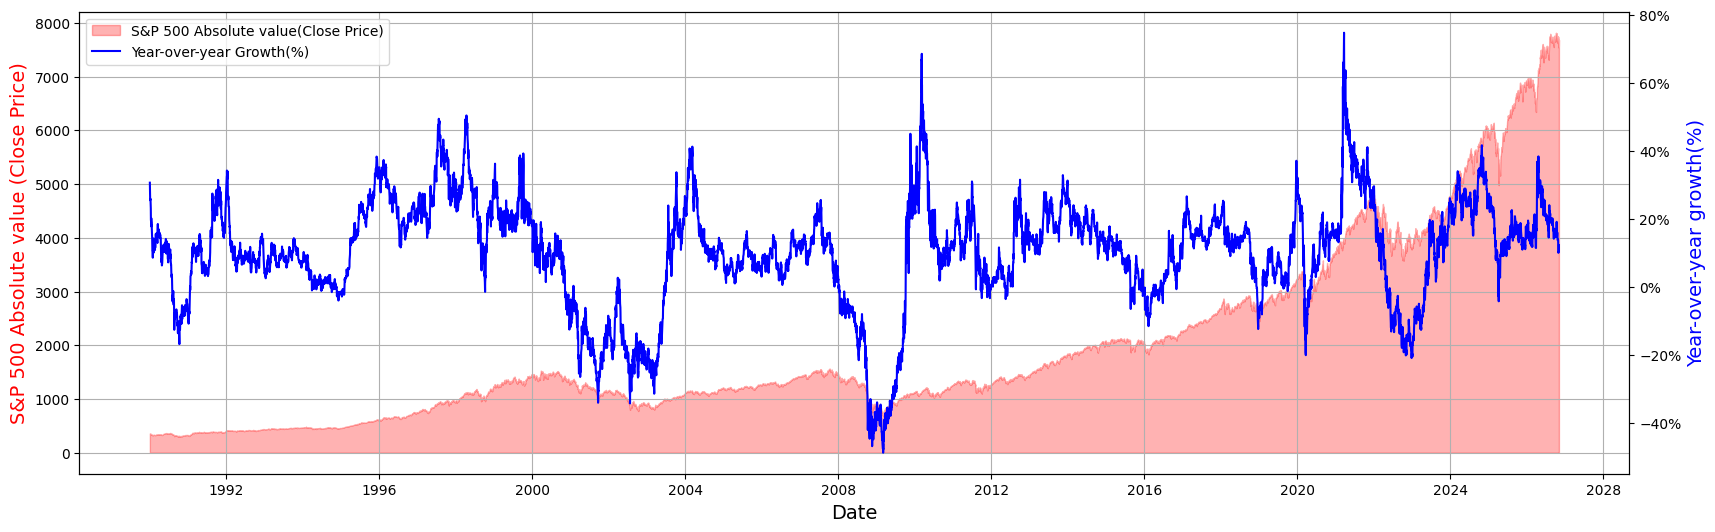

In [19]:
#plotting the graph
fig,ax = plt.subplots(figsize = (20,6))
plt.grid(True)

#plotting area under the actual
ax.fill_between(spx_truncated.index,spx_truncated.Close, color = "red",alpha = 0.3, label = "S&P 500 Absolute value(Close Price)")

#Creating a secondary Y-axis for the cpi growth Percentage
ax2 = ax.twinx()
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax2.plot(spx_truncated.spx_yoy, color = "blue",
        #marker="."
        label = "Year-over-year Growth(%)")
#setting labels and titles
ax.set_xlabel("Date", fontsize = 14)
ax.set_ylabel("S&P 500 Absolute value (Close Price)",color = "red",fontsize = 14)
ax2.set_ylabel("Year-over-year growth(%)",color = "blue",fontsize = 14)

#Adding the legend
lines,labels = ax.get_legend_handles_labels()
lines2,labels2 =ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc ="upper left")
plt.show()

In [20]:
#Data sources for stocks
#Indexes fpr from yahoo finance
#Dax index(XETRA- XETRA Delayed price.currency in Eur)
#Web.https://finance.yahoo.com/quote/%5EGDAXI
dax_daily = yf.download(tickers = "^GDAXI",period = "max", interval= "1d", auto_adjust= False)
dax_daily

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,^GDAXI,^GDAXI,^GDAXI,^GDAXI,^GDAXI,^GDAXI
Date,,,,,,
1987-12-30,1005.190002,1005.190002,1005.190002,1005.190002,1005.190002,0
1988-01-04,956.489990,956.489990,956.489990,956.489990,956.489990,0
1988-01-05,996.099976,996.099976,996.099976,996.099976,996.099976,0
1988-01-06,1006.010010,1006.010010,1006.010010,1006.010010,1006.010010,0
1988-01-07,1014.469971,1014.469971,1014.469971,1014.469971,1014.469971,0
...,...,...,...,...,...,...
2026-10-30,25818.210938,25818.210938,26026.199219,25779.150391,25948.609375,53853200
2026-11-02,25981.089844,25981.089844,26022.259766,25741.570312,25802.740234,51950600


In [21]:
dax_daily.tail()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,^GDAXI,^GDAXI,^GDAXI,^GDAXI,^GDAXI,^GDAXI
Date,,,,,,
2026-10-30,25818.210938,25818.210938,26026.199219,25779.150391,25948.609375,53853200
2026-11-02,25981.089844,25981.089844,26022.259766,25741.570312,25802.740234,51950600
2026-11-03,25864.619141,25864.619141,26037.279297,25677.859375,25730.060547,59045400
2026-11-04,26437.669922,26437.669922,26541.640625,25876.820312,25888.929688,93436800
2026-11-05,26619.429688,26619.429688,26692.900391,26445.449219,26449.789062,0


In [22]:
# Flatten MultiIndex columns
if isinstance(dax_daily.columns, pd.MultiIndex):
    dax_daily.columns = dax_daily.columns.droplevel('Ticker')


In [23]:
dax_daily['adj_close_last_year'] = dax_daily['Adj Close'].shift(252)
dax_daily['yoy_growth'] = dax_daily['Adj Close'] /dax_daily['adj_close_last_year']-1

dax_daily

# normally 252 trading days
#dax_daily['close_last_year'] = dax_daily[' close'].shift(252)
#dax_daily['yoy_growth'] = dax_daily[' close'] / dax_daily['close_last_year'] -1

Price,Adj Close,Close,High,Low,Open,Volume,adj_close_last_year,yoy_growth
Date,,,,,,,,
1987-12-30,1005.190002,1005.190002,1005.190002,1005.190002,1005.190002,0,NaN,NaN
1988-01-04,956.489990,956.489990,956.489990,956.489990,956.489990,0,NaN,NaN
1988-01-05,996.099976,996.099976,996.099976,996.099976,996.099976,0,NaN,NaN
1988-01-06,1006.010010,1006.010010,1006.010010,1006.010010,1006.010010,0,NaN,NaN
1988-01-07,1014.469971,1014.469971,1014.469971,1014.469971,1014.469971,0,NaN,NaN
...,...,...,...,...,...,...,...,...
2026-10-30,25818.210938,25818.210938,26026.199219,25779.150391,25948.609375,53853200,23958.300781,0.077631
2026-11-02,25981.089844,25981.089844,26022.259766,25741.570312,25802.740234,51950600,24132.410156,0.076606
2026-11-03,25864.619141,25864.619141,26037.279297,25677.859375,25730.060547,59045400,23949.109375,0.079983


In [24]:
#I want to do a quick check now
print(dax_daily.columns)
print(dax_daily['Close'].shape)

Index(['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume',
       'adj_close_last_year', 'yoy_growth'],
      dtype='object', name='Price')
(9826,)


In [25]:
# Now I want to sort  the problem with mulitiIndex once and for all so that I do not hit the same pattern of errors again
#Creating the clean_yf function
def clean_yf(df):
    df = df.copy()
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.droplevel('Ticker')
    return df
#

In [26]:
#dax_daily = clean_yf(yf.download("^GDAXI", start=start, end=end, auto_adjust = False))
#spx_index = clean_yf(yf.download("^GSPC", start=start, end=end, auto_adjust = False))

In [27]:
dax_daily

Price,Adj Close,Close,High,Low,Open,Volume,adj_close_last_year,yoy_growth
Date,,,,,,,,
1987-12-30,1005.190002,1005.190002,1005.190002,1005.190002,1005.190002,0,NaN,NaN
1988-01-04,956.489990,956.489990,956.489990,956.489990,956.489990,0,NaN,NaN
1988-01-05,996.099976,996.099976,996.099976,996.099976,996.099976,0,NaN,NaN
1988-01-06,1006.010010,1006.010010,1006.010010,1006.010010,1006.010010,0,NaN,NaN
1988-01-07,1014.469971,1014.469971,1014.469971,1014.469971,1014.469971,0,NaN,NaN
...,...,...,...,...,...,...,...,...
2026-10-30,25818.210938,25818.210938,26026.199219,25779.150391,25948.609375,53853200,23958.300781,0.077631
2026-11-02,25981.089844,25981.089844,26022.259766,25741.570312,25802.740234,51950600,24132.410156,0.076606
2026-11-03,25864.619141,25864.619141,26037.279297,25677.859375,25730.060547,59045400,23949.109375,0.079983


In [28]:
print(dax_daily.columns)
print(dax_daily['Close'].shape)

Index(['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume',
       'adj_close_last_year', 'yoy_growth'],
      dtype='object', name='Price')
(9826,)


<Axes: xlabel='Date'>

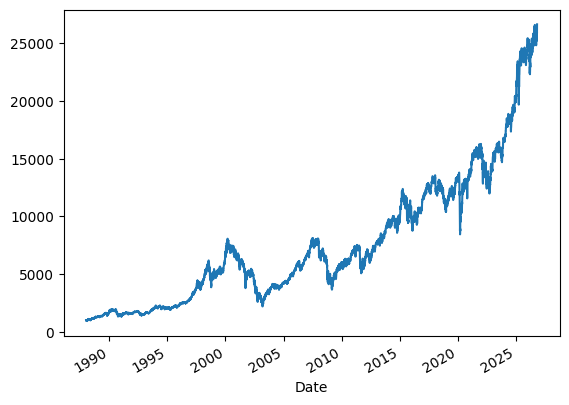

In [29]:
dax_daily['Adj Close'].plot.line()

In [30]:
#Delayed 15 mins: https://finance.com/quote/%5ESPX/
#S#P 500 INDEX:Chicago options- chicago options Delayed prices.currency in USD
snp500_daily = clean_yf(yf.download(tickers="^GSPC",period="max",interval="1d"))

[*********************100%***********************]  1 of 1 completed


In [31]:
snp500_daily.tail()

Price,Close,High,Low,Open,Volume
Date,,,,,
2026-10-30,7580.069824,7637.479980,7527.560059,7631.069824,6149170000
2026-11-02,7541.399902,7662.229980,7539.379883,7610.830078,5712790000
2026-11-03,7568.919922,7594.609863,7545.390137,7552.919922,5481240000
2026-11-04,7688.620117,7715.569824,7635.810059,7635.810059,7390830000
2026-11-05,7626.200195,7681.290039,7626.200195,7678.720215,270292046


In [32]:
snp500_daily_non_delayed = clean_yf(yf.download(tickers ="^GSPC",period="max",interval ="1d"))
snp500_daily_non_delayed.tail()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Date,,,,,
2026-10-30,7580.069824,7637.479980,7527.560059,7631.069824,6149170000
2026-11-02,7541.399902,7662.229980,7539.379883,7610.830078,5712790000
2026-11-03,7568.919922,7594.609863,7545.390137,7552.919922,5481240000
2026-11-04,7688.620117,7715.569824,7635.810059,7635.810059,7390830000
2026-11-05,7626.450195,7681.290039,7626.200195,7678.720215,271004531


In [33]:
#dow jones industrial average:https://finance.yahoo.com/quoted/%5EDJI?.tsrc=fin-srch
dji_daily = clean_yf(yf.download(tickers ="^DJI",period ="max",interval ="1d"))
dji_daily.tail()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Date,,,,,
2026-10-30,51770.308594,52383.898438,51563.761719,52383.898438,659020000
2026-11-02,51983.980469,52424.910156,51981.660156,52008.230469,522040000
2026-11-03,51786.718750,51932.628906,51593.160156,51932.628906,423180000
2026-11-04,53356.121094,53492.398438,52410.230469,52410.230469,712500000
2026-11-05,53508.980469,53710.609375,53480.308594,53679.011719,56744239


In [34]:
# https://finance.yahoo.com/quote/VOO?.tsrc=fin-srch
voo_etf = clean_yf(yf.download(tickers = "VOO",period = "max", interval = "1d", auto_adjust = False))
voo_etf.tail()


[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2026-10-30,694.809998,694.809998,700.010010,689.750000,699.919983,9983800
2026-11-02,691.320007,691.320007,702.140015,690.880005,698.099976,8401200
2026-11-03,693.539978,693.539978,695.900024,691.630005,691.880005,6279900
2026-11-04,704.780029,704.780029,707.090027,701.090027,701.330017,6915700
2026-11-05,699.039978,699.039978,704.099976,699.000000,701.330017,1261018


In [35]:
# ETFs
# WisdomTree India Earnings Fund (EPI)
# NYSEArca - Nasdaq Real Time Price. Currency in USD
# WEB: https://finance.yahoo.com/quote/EPI/history?p=EPI
epi_etf_daily = clean_yf(yf.download(tickers = "EPI",period = "max",interval = "1d",auto_adjust = False))

[*********************100%***********************]  1 of 1 completed


In [36]:
epi_etf_daily.head()
print(epi_etf_daily.shape)

(4705, 6)


In [37]:
epi_etf_daily.head()

Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2008-02-26,21.446682,26.160000,26.270000,25.700001,25.920000,813800
2008-02-27,21.372892,26.070000,26.270000,25.860001,26.129999,881900
2008-02-28,21.069557,25.700001,26.030001,25.660000,25.980000,1037000
2008-02-29,20.339911,24.809999,25.330000,24.730000,25.330000,854700
2008-03-03,19.790625,24.139999,24.330000,23.879999,24.230000,610000


In [38]:
epi_etf_daily.tail()

Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2026-10-30,40.970001,40.970001,41.020000,40.689999,40.689999,431200
2026-11-02,41.689999,41.689999,41.830002,41.520000,41.520000,888500
2026-11-03,41.660000,41.660000,41.900002,41.660000,41.880001,673900
2026-11-04,42.919998,42.919998,43.000000,42.570000,42.570000,808600
2026-11-05,42.869999,42.869999,43.000000,42.869999,42.570000,37574


In [39]:
# find dividends impact on Close vs. Adj.Close
epi_etf_daily[(epi_etf_daily.index >='2023-06-23') & (epi_etf_daily.index <='2023-06-28')]

Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2023-06-23,33.870712,34.020000,34.150002,33.930000,34.029999,344100
2023-06-26,33.990395,34.080002,34.160000,34.049999,34.110001,634600
2023-06-27,34.219791,34.310001,34.310001,34.230000,34.279999,417100
2023-06-28,34.439209,34.529999,34.529999,34.389999,34.410000,454400


In [40]:
# find dividends - diff for Close vs. Adj Close
# Open/Close for 06-25 diff is close to divs = 1.845 (~1.58 for Open and 1.3 for Close)
# HELP: https://help.yahoo.com/kb/SLN28256.html#:~:text=Adjusted%20close%20is%20the%20closing,Security%20Prices%20(CRSP)%20standards.
epi_etf_daily[(epi_etf_daily.index >='2022-06-23') & (epi_etf_daily.index <='2022-06-28')]
     

Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2022-06-23,29.226185,31.200001,31.26,31.000000,31.129999,607700
2022-06-24,29.768791,29.900000,29.91,29.500000,29.549999,387900
2022-06-27,29.579622,29.709999,29.82,29.660000,29.799999,225400
2022-06-28,29.290897,29.420000,29.76,29.389999,29.709999,466600


<Axes: title={'center': "EPI's etf stock price"}, xlabel='Date'>

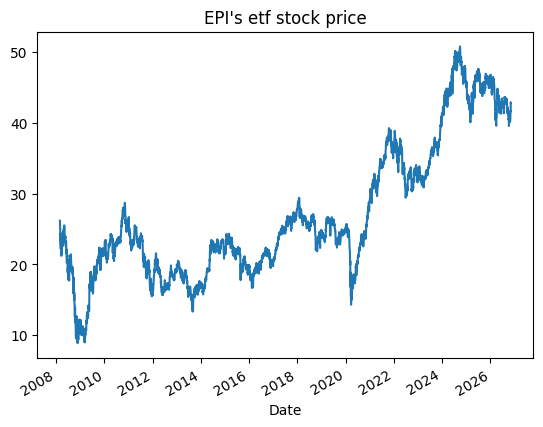

In [41]:
# About yFinance: https://zoo.cs.yale.edu/classes/cs458/lectures/yfinance.html
epi_etf_daily['Close'].plot(title="EPI's etf stock price")

In [42]:
#get_actions, inc. dividends as a DataFrame
epi = yf.Ticker('EPI')
epi.get_actions()

,Dividends
Date,
2008-12-22 00:00:00-05:00,0.091
2009-03-23 00:00:00-04:00,0.007
2009-06-22 00:00:00-04:00,0.002
2009-09-21 00:00:00-04:00,0.045
2009-12-21 00:00:00-05:00,0.006
2010-06-28 00:00:00-04:00,0.065
2010-09-20 00:00:00-04:00,0.065
2010-12-22 00:00:00-05:00,0.013
2011-06-22 00:00:00-04:00,0.062


In [43]:
dividends = epi.get_actions()
dividends[(dividends.index >= '2023-06-01') & (dividends.index <= '2023-07-01')]

,Dividends
Date,
2023-06-26 00:00:00-04:00,0.06


In [44]:
# get dividends as Series
epi.get_dividends()

Date
2008-12-22 09:30:00-05:00    0.091
2009-03-23 09:30:00-04:00    0.007
2009-06-22 09:30:00-04:00    0.002
2009-09-21 09:30:00-04:00    0.045
2009-12-21 09:30:00-05:00    0.006
2010-06-28 09:30:00-04:00    0.065
2010-09-20 09:30:00-04:00    0.065
2010-12-22 09:30:00-05:00    0.013
2011-06-22 09:30:00-04:00    0.062
2011-09-26 09:30:00-04:00    0.098
2012-03-26 09:30:00-04:00    0.010
2012-06-25 09:30:00-04:00    0.045
2012-09-24 09:30:00-04:00    0.083
2012-12-24 09:30:00-05:00    0.024
2013-06-24 09:30:00-04:00    0.068
2013-09-23 09:30:00-04:00    0.063
2014-03-24 09:30:00-04:00    0.099
2014-06-23 09:30:00-04:00    0.059
2014-09-22 09:30:00-04:00    0.068
2015-03-23 09:30:00-04:00    0.031
2015-06-22 09:30:00-04:00    0.067
2015-09-21 09:30:00-04:00    0.116
2015-12-21 09:30:00-05:00    0.024
2016-03-21 09:30:00-04:00    0.010
2016-06-20 09:30:00-04:00    0.125
2016-09-26 09:30:00-04:00    0.070
2016-12-23 09:30:00-05:00    0.006
2017-03-27 09:30:00-04:00    0.075
2017-06-26 09:3

In [45]:
# Please read the article (section "Polygon.io News API"): https://pythoninvest.com/long-read/chatgpt-api-for-financial-news-summarization
     

In [46]:
# Endpoint: https://polygon.io/docs/stocks/get_v2_reference_news

MACROECONOMICS

In [47]:
# Gold reserves excl. gold for China
# https://fred.stlouisfed.org/series/TRESEGCNM052N
gold_reserves = pdr.DataReader("TRESEGCNM052N", "fred", start=start)

<Axes: xlabel='DATE'>

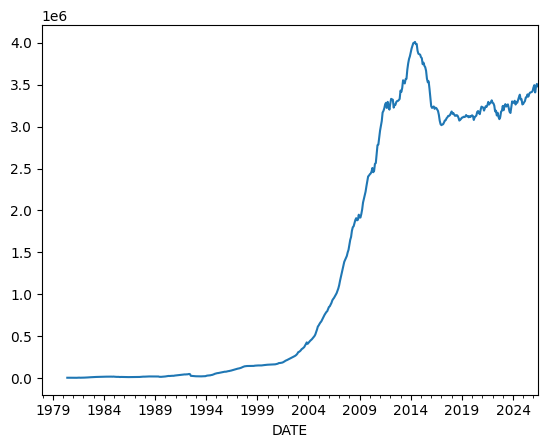

In [48]:
gold_reserves.TRESEGCNM052N.plot.line()

In [49]:
#  CBOE Gold ETF Volatility Index (GVZCLS)
# https://fred.stlouisfed.org/series/GVZCLS
gold_volatility = pdr.DataReader("GVZCLS", "fred", start=start)

<Axes: xlabel='DATE'>

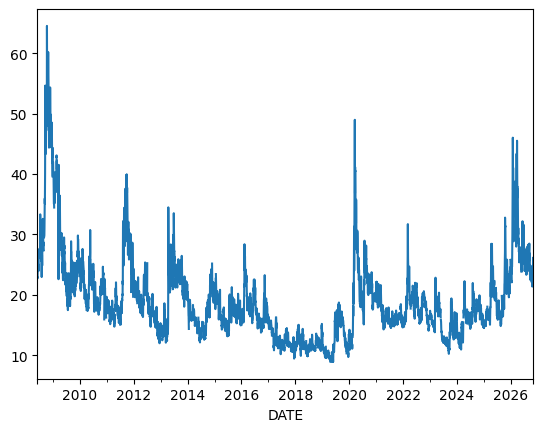

In [50]:
gold_volatility.GVZCLS.plot.line()

In [51]:
#  Crude Oil Prices: West Texas Intermediate (WTI) - Cushing, Oklahoma (DCOILWTICO)
# https://fred.stlouisfed.org/series/DCOILWTICO
oil_wti = pdr.DataReader("DCOILWTICO", "fred", start=start)

<Axes: xlabel='DATE'>

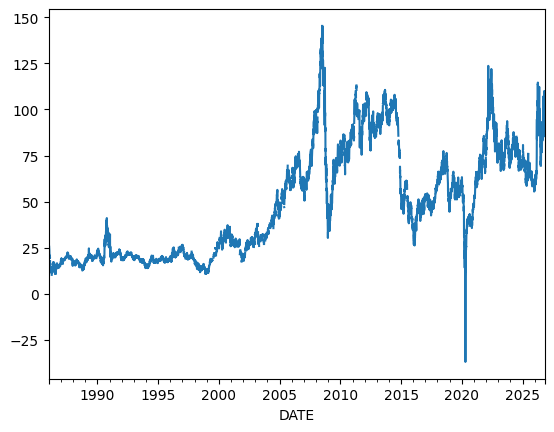

In [52]:
# there is a bug in the data? negative price?
oil_wti.DCOILWTICO.plot.line()

In [53]:
# Crude Oil Prices: Brent - Europe (DCOILBRENTEU)
# https://fred.stlouisfed.org/series/DCOILBRENTEU
oil_brent = pdr.DataReader("DCOILBRENTEU", "fred", start=start)

<Axes: xlabel='DATE'>

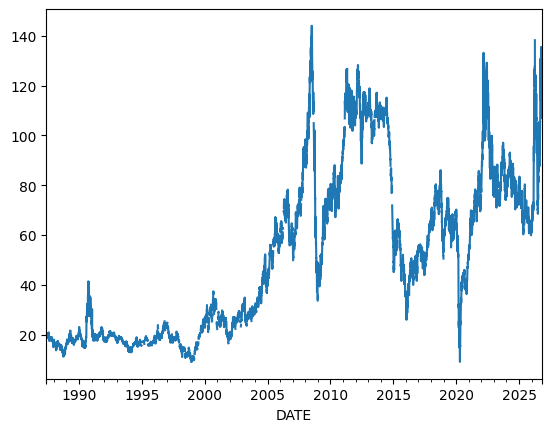

In [54]:
oil_brent.DCOILBRENTEU.plot.line()

In [55]:
#Web scrapping for macros
#cannot call directly via pd.read_html as it returns 403(forbidden)--> still need to do a bit of work but still no selenium
import requests
from bs4 import BeautifulSoup

url = "https://tradingeconomics.com/united-states/indicators"

headers = {
     "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/58.0.3029.110 Safari/537.3"
}
response = requests.get(url,headers = headers)

In [56]:
#check if the request was successfull status code == 200
if response.status_code == 200:
    #parse the html content of the webpage
    soup = BeautifulSoup(response.content,"html.parser")
    #you need to be able to find the table tag and read all behind it
    #find the div with class"table-responsive"
    table_div = soup.find("div",class_ = "table-responsive")
    #extract the tabel within the div
    table = table_div.find("table")
    #use pandas to read the table into a dataframe
    df = pd.read_html(str(table))[0]
    #Assuming there is only one table otherwise loop through the list
    #display the dataframe
    print(df)
else:
    print("Failed to retrieve the data from the webpage")

                  Unnamed: 0    Last  Previous  Highest    Lowest  \
0                   Currency   102.0     102.0   165.00     70.70   
1               Stock Market  7684.0    7689.0  7845.00      4.40   
2            GDP Growth Rate     3.4       2.2    34.90    -28.00   
3     GDP Annual Growth Rate     3.4       2.2    13.40     -7.40   
4          Unemployment Rate     4.2       4.1    14.80      2.50   
5          Non Farm Payrolls    29.0     133.0  4631.00 -20469.00   
6             Inflation Rate     3.7       3.4    23.70    -15.80   
7         Inflation Rate MoM     0.6       0.4     2.00     -1.80   
8              Interest Rate     4.0       4.0    20.00      0.25   
9           Balance of Trade  -105.0    -106.0     1.95   -133.00   
10           Current Account  -246.0    -213.0     9.96   -438.00   
11    Current Account to GDP    -3.6      -4.0     0.20     -6.00   
12    Government Debt to GDP   123.0     122.0   126.00     31.80   
13         Government Budget    -5

/var/folders/2d/1c91gggs08n6vxd8g4bhwqmc0001yj/T/ipykernel_81101/2735832407.py:11: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  df = pd.read_html(str(table))[0]


In [57]:
df

,Unnamed: 0,Last,Previous,Highest,Lowest,Unnamed: 5,Unnamed: 6
0,Currency,102.0,102.0,165.00,70.70,NaN,Nov/26
1,Stock Market,7684.0,7689.0,7845.00,4.40,points,Nov/26
2,GDP Growth Rate,3.4,2.2,34.90,-28.00,percent,Sep/26
3,GDP Annual Growth Rate,3.4,2.2,13.40,-7.40,percent,Sep/26
4,Unemployment Rate,4.2,4.1,14.80,2.50,percent,Sep/26
5,Non Farm Payrolls,29.0,133.0,4631.00,-20469.00,Thousand,Sep/26
6,Inflation Rate,3.7,3.4,23.70,-15.80,percent,Sep/26
7,Inflation Rate MoM,0.6,0.4,2.00,-1.80,percent,Sep/26
8,Interest Rate,4.0,4.0,20.00,0.25,percent,Oct/26
9,Balance of Trade,-105.0,-106.0,1.95,-133.00,USD Billion,Sep/26


FINANCIAL REPORTING WITH EDGAR

In [58]:
#Lets check for NVDA
nvda = yf.Ticker('NVDA')

In [59]:
#Yearly financials for the last 4 years
nvda.financials

,2026-01-31,2025-01-31,2024-01-31,2023-01-31,2022-01-31
Tax Effect Of Unusual Items,0.000000e+00,0.000000e+00,0.000000e+00,-3.486681e+08,NaN
Tax Rate For Calcs,1.511700e-01,1.326490e-01,1.200000e-01,2.577000e-01,NaN
Normalized EBITDA,1.445520e+11,8.613700e+10,3.558300e+10,7.339000e+09,NaN
Total Unusual Items,NaN,0.000000e+00,0.000000e+00,-1.353000e+09,0.0
Total Unusual Items Excluding Goodwill,NaN,0.000000e+00,0.000000e+00,-1.353000e+09,0.0
Net Income From Continuing Operation Net Minority Interest,1.200670e+11,7.288000e+10,2.976000e+10,4.368000e+09,NaN
Reconciled Depreciation,2.843000e+09,1.864000e+09,1.508000e+09,1.543000e+09,NaN
Reconciled Cost Of Revenue,6.247500e+10,3.263900e+10,1.662100e+10,1.161800e+10,NaN
EBITDA,1.445520e+11,8.613700e+10,3.558300e+10,5.986000e+09,NaN
EBIT,1.417090e+11,8.427300e+10,3.407500e+10,4.443000e+09,NaN


In [60]:
#balance sheets
nvda.balance_sheet

,2026-01-31,2025-01-31,2024-01-31,2023-01-31,2022-01-31
Ordinary Shares Number,2.430400e+10,2.447700e+10,2.464000e+10,2.466137e+10,NaN
Share Issued,2.430400e+10,2.447700e+10,2.464000e+10,2.466137e+10,NaN
Net Debt,NaN,NaN,2.429000e+09,7.564000e+09,8.956000e+09
Total Debt,1.104000e+10,9.982000e+09,1.105600e+10,1.203100e+10,NaN
Tangible Book Value,1.331550e+11,7.333200e+10,3.743600e+10,1.605300e+10,NaN
...,...,...,...,...,...
Receivables,3.846600e+10,2.306500e+10,9.999000e+09,3.827000e+09,NaN
Accounts Receivable,3.846600e+10,2.306500e+10,9.999000e+09,3.827000e+09,NaN
Cash Cash Equivalents And Short Term Investments,6.255600e+10,4.321000e+10,2.598400e+10,1.329600e+10,NaN
Other Short Term Investments,5.195100e+10,3.462100e+10,1.870400e+10,9.907000e+09,NaN


In [61]:
#basic info
nvda.fast_info

lazy-loading dict with keys = ['currency', 'dayHigh', 'dayLow', 'exchange', 'fiftyDayAverage', 'lastPrice', 'lastVolume', 'marketCap', 'open', 'previousClose', 'quoteType', 'regularMarketPreviousClose', 'shares', 'tenDayAverageVolume', 'threeMonthAverageVolume', 'timezone', 'twoHundredDayAverage', 'yearChange', 'yearHigh', 'yearLow']

In [62]:
#Marketcap is quite useful,but do not know when it was updated?daily?
nvda.fast_info['marketCap']/1e9

4648.659690261841

In [63]:
#read this article for full info: https://zoo.cs.yale.edu/classes/cs458/lectures/yfinance.html    

In [64]:
import requests
from bs4 import BeautifulSoup

# URL of the webpage
url = "https://companiesmarketcap.com/"

# Define headers with a user-agent to mimic a web browser
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/58.0.3029.110 Safari/537.3"
}

# Send a GET request to the URL with headers
response = requests.get(url, headers=headers)

# Check if the request was successful (status code 200)
if response.status_code == 200:
    # Parse the HTML content of the webpage
    soup = BeautifulSoup(response.content, "html.parser")

    # Find the download link within the webpage
    download_link = soup.find("a", {"rel": "nofollow", "href": "?download=csv"})

    # If the download link is found
    if download_link:
        # Extract the href attribute which contains the actual download link
        download_url = 'https://companiesmarketcap.com/'+download_link["href"]

        # Download the CSV file using the obtained download URL
        download_response = requests.get(download_url, headers=headers)

        # Check if the download request was successful
        if download_response.status_code == 200:
            # Save the content of the response to a local file
            with open("global_stocks.csv", "wb") as f:
                f.write(download_response.content)
            print("CSV file downloaded successfully.")
        else:
            print("Failed to download the CSV file.")
    else:
        print("Download link not found on the webpage.")
else:
    print("Failed to retrieve data from the webpage.")

CSV file downloaded successfully.


In [65]:
global_stocks = pd.read_csv("global_stocks.csv")

In [66]:
global_stocks['marketcap_b_usd'] = global_stocks.marketcap/1e9

In [67]:
global_stocks.head(10)

,Rank,Name,Symbol,marketcap,price (USD),country,marketcap_b_usd
0,1,Apple,AAPL,5140759183360,353.75000,United States,5140.759183
1,2,NVIDIA,NVDA,4645955043328,192.40300,United States,4645.955043
2,3,Microsoft,MSFT,4116673462272,554.34500,United States,4116.673462
3,4,Alphabet (Google),GOOG,3557145706496,289.34000,United States,3557.145706
4,5,Amazon,AMZN,2918249660416,269.88000,United States,2918.249660
5,6,TSMC,TSM,1952344965120,376.43000,Taiwan,1952.344965
6,7,SpaceX,SPCX,1747882868736,128.70000,United States,1747.882869
7,8,Saudi Aramco,2222.SR,1687141130640,6.97433,Saudi Arabia,1687.141131
8,9,Meta Platforms (Facebook),META,1596972466176,624.59000,United States,1596.972466
9,10,Broadcom,AVGO,1481830301696,310.42000,United States,1481.830302


In [68]:
global_stocks.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11396 entries, 0 to 11395
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Rank             11396 non-null  int64  
 1   Name             11396 non-null  object 
 2   Symbol           11395 non-null  object 
 3   marketcap        11396 non-null  int64  
 4   price (USD)      11396 non-null  float64
 5   country          11396 non-null  object 
 6   marketcap_b_usd  11396 non-null  float64
dtypes: float64(2), int64(2), object(3)
memory usage: 623.3+ KB


In [70]:
import requests
from bs4 import BeautifulSoup

url = "https://www.gurufocus.com/economic_indicators/229/dow-jones-industrial-average-djia"

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/58.0.3029.110 Safari/537.3"
}
response = requests.get(url,headers = headers)
if response.status_code == 200:
    soup = BeautifulSoup(response.content,"html.parser")
    table_div = soup.find("div",class_ = "table_responsive")
    table = table_div.find("table")
    df = pd.read_html(str(table))[0]
    print(df)
else:
    print("failed to retrieve data from the webpage")

ConnectTimeout: HTTPSConnectionPool(host='www.gurufocus.com', port=443): Max retries exceeded with url: /economic_indicators/229/dow-jones-industrial-average-djia (Caused by ConnectTimeoutError(<HTTPSConnection(host='www.gurufocus.com', port=443) at 0x122089b40>, 'Connection to www.gurufocus.com timed out. (connect timeout=None)'))